# RF-DETR majority-vote ensemble

Models: **RF-DETR erasing 10** (base), **erasing + dropout 0.1**, **erasing + dropout 0.2**, evaluated on the val and test splits.

1. RF-DETR erasing 10 on its own, as the baseline
2. The majority-vote ensemble, compared with each individual model

Voting, per box predicted by the base model (RF-DETR erasing 10):
- each other model votes with the class of its highest-confidence box overlapping the base box (IoU >= `MATCH_IOU`), counted only if that box is a real output (confidence >= `VOTE_CONF`)
- if at least 2 of the 3 models agree on a class, the box takes that class
- otherwise the box keeps the base model's class

The box and its confidence always stay the base model's: voting only changes the class. (Taking the voters' confidence instead would lift
RF-DETR's low-confidence wrong-class copies of a box to high confidence, flooding the output with duplicate detections.)

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import yaml
from collections import Counter
from pathlib import Path
from supervision.metrics import MeanAveragePrecision, Precision, Recall, AveragingMethod
from rfdetr import from_checkpoint

TEXT, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

CUDA available: True
GPU: NVIDIA GeForce RTX 3070


In [24]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]  # ai-applications/vs_notebooks -> repo root

DATASET_DIR = PROJECT_ROOT / 'data' / 'wildlife_dataset'
DATA = DATASET_DIR / 'wildlife_dataset.yaml'
TRAINED_MODEL_DIR = PROJECT_ROOT / 'ai-applications' / 'trained_models'
RESULTS_DIR = PROJECT_ROOT / 'ai-applications' / 'training_results' / 'rf-detr-ensemble-vote'

# The first model is the base: its boxes are voted on and its class is the fallback
BASE_NAME = 'RF-DETR erasing 10'
MODELS = {
    BASE_NAME: TRAINED_MODEL_DIR / 'rfdetr_erasing_10_best.pth',
    'RF-DETR erasing + dropout 0.1': TRAINED_MODEL_DIR / 'rfdetr_erasing_dropout_10_best.pth',
    'RF-DETR erasing + dropout 0.2': TRAINED_MODEL_DIR / 'rfdetr_erasing_dropout_20_best.pth',
}
ENSEMBLE_NAME = 'Ensemble (majority vote)'

SPLITS = ['val', 'test']
PREDICT_THRESHOLD = 0.01  # keep low-confidence boxes so mAP sees the full precision-recall curve
MATCH_IOU = 0.5  # boxes from different models at or above this IoU are treated as the same object
VOTE_CONF = 0.5  # another model's box only votes if it would be an actual output (individual best-F1 confidences are 0.4-0.7)
EVAL_IOU = 0.5  # IoU for precision / recall / confusion matrix (same as precision_at_50)

assert DATASET_DIR.exists(), f'Dataset not found: {DATASET_DIR}'
for path in MODELS.values():
    assert path.exists(), f'Model not found: {path}'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA, 'r') as f:
    names = yaml.safe_load(f)['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)

print('Dataset:', DATASET_DIR)
print('Results dir:', RESULTS_DIR)
print('Classes:', CLASS_NAMES)

Dataset: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Results dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-ensemble-vote
Classes: ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


## Metrics

In [25]:
def evaluate(predictions, targets):
    map_result = MeanAveragePrecision().update(predictions, targets).compute()

    # Precision / recall at the confidence with the best F1 (same convention as the training notebooks)
    best = {'F1': -1.0}
    for conf in np.arange(0.05, 0.96, 0.05):
        kept = [p[p.confidence >= conf] for p in predictions]
        precision = Precision(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().precision_at_50
        recall = Recall(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().recall_at_50
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        if f1 > best['F1']:
            best = {'Precision': float(precision), 'Recall': float(recall), 'F1': float(f1), 'Confidence': round(float(conf), 2)}

    return {
        'Precision': best['Precision'],
        'Recall': best['Recall'],
        'F1': best['F1'],
        'mAP50': float(map_result.map50),
        'mAP75': float(map_result.map75),
        'mAP50-95': float(map_result.map50_95),
        'Best-F1 confidence': best['Confidence'],
    }, map_result


def per_class_ap(map_result):
    ap = pd.DataFrame(index=CLASS_NAMES, columns=['AP50', 'AP50-95'], dtype=float)
    for class_id, row in zip(map_result.matched_classes, map_result.ap_per_class):
        ap.loc[CLASS_NAMES[int(class_id)]] = [row[0], row.mean()]
    return ap


def confusion_counts(predictions, targets, conf_threshold):
    # rows = true, columns = predicted, last row/column = background
    return sv.ConfusionMatrix.from_detections(
        predictions=predictions,
        targets=targets,
        classes=CLASS_NAMES,
        conf_threshold=conf_threshold,
        iou_threshold=EVAL_IOU
    ).matrix.astype(int)


def per_class_table(counts):
    tp = np.diag(counts)[:-1]
    fp = counts[:, :-1].sum(axis=0) - tp  # predicted as the class, but the true class / background differs
    fn = counts[:-1, :].sum(axis=1) - tp  # true class predicted as another class or missed
    animals = counts[:-1, :-1]
    table = pd.DataFrame({
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Wrong class': animals.sum(axis=1) - tp,
        'Missed': counts[:-1, -1],
        'False detections': counts[-1, :-1],
    }, index=CLASS_NAMES)
    table['Precision'] = tp / np.maximum(tp + fp, 1)
    table['Recall'] = tp / np.maximum(tp + fn, 1)
    table['F1'] = 2 * table['Precision'] * table['Recall'] / (table['Precision'] + table['Recall'] + 1e-9)
    # Of the animals the model found, how many got the right label
    table['Classification accuracy'] = tp / np.maximum(tp + table['Wrong class'], 1)
    return table


def report_details(name, file_tag):
    """Per-class AP, confusion matrix (printed + plotted) and per-class P/R/F1 of one model on every split."""
    labels = CLASS_NAMES + ['background']
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(7 * len(SPLITS), 6))

    for ax, split in zip(np.atleast_1d(axes), SPLITS):
        metrics, map_result = results[split][name]
        conf_threshold = metrics['Best-F1 confidence']
        counts = confusion_counts(predictions[split][name], targets[split], conf_threshold)

        print(f'\n{"=" * 30} [{split}] {name} {"=" * 30}')
        print('\nPer-class AP')
        print(per_class_ap(map_result).round(4).to_string())

        matrix = pd.DataFrame(counts, index=[f'true {l}' for l in labels], columns=[f'pred {l}' for l in labels])
        matrix.to_csv(RESULTS_DIR / f'{file_tag}_confusion_matrix_{split}.csv')
        print(f'\nConfusion matrix (conf >= {conf_threshold}, IoU {EVAL_IOU})')
        print(matrix.to_string())

        per_class = per_class_table(counts)
        per_class.to_csv(RESULTS_DIR / f'{file_tag}_confusion_per_class_{split}.csv')
        print('\nPer-class precision / recall / F1 (from the confusion matrix)')
        print(per_class.round(4).to_string())

        # Shade each true class by its share of that row; the background row has no true total, so leave it unshaded
        row_share = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
        row_share[-1] = 0
        ax.imshow(row_share, cmap='Blues', vmin=0, vmax=1)
        for i in range(len(labels)):
            for j in range(len(labels)):
                if counts[i, j]:
                    ax.text(j, i, counts[i, j], ha='center', va='center', fontsize=11,
                            color='white' if row_share[i, j] > 0.5 else TEXT)
        ax.set_xticks(range(len(labels)), labels, rotation=30, ha='right')
        ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel('Predicted', color=MUTED)
        ax.set_ylabel('True', color=MUTED)
        ax.set_title(f'{name}: {split} (conf >= {conf_threshold}, IoU 0.5)', loc='left', fontsize=12, color=TEXT)
        ax.tick_params(colors=MUTED, length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{file_tag}_confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

## Load models and data

In [26]:
models = {}
for name, path in MODELS.items():
    models[name] = from_checkpoint(path)
    print(f'Loaded {name}: {path.name}')

datasets, targets = {}, {}
for split in SPLITS:
    datasets[split] = sv.DetectionDataset.from_yolo(
        images_directory_path=str(DATASET_DIR / 'images' / split),
        annotations_directory_path=str(DATASET_DIR / 'labels' / split),
        data_yaml_path=str(DATA)
    )
    targets[split] = [annotations for _, _, annotations in datasets[split]]
    print(f'{split}: {len(datasets[split])} images, {sum(len(t) for t in targets[split])} ground-truth boxes')

# predictions[split][model name] -> list of sv.Detections, one per image; results[split][model name] -> (metrics, map_result)
predictions = {split: {} for split in SPLITS}
results = {split: {} for split in SPLITS}

[2026-10-19 22:08:13] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-19 22:08:13] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-19 22:08:14] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-19 22:08:14] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loaded RF-DETR erasing 10: rfdetr_erasing_10_best.pth


[2026-10-19 22:08:14] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-19 22:08:14] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loaded RF-DETR erasing + dropout 0.1: rfdetr_erasing_dropout_10_best.pth
Loaded RF-DETR erasing + dropout 0.2: rfdetr_erasing_dropout_20_best.pth
val: 332 images, 457 ground-truth boxes
test: 331 images, 474 ground-truth boxes


## RF-DETR erasing 10 (baseline)

Inference on val and test with the base model alone. The ensemble below reuses these predictions.

In [27]:
for split in SPLITS:
    image_paths = datasets[split].image_paths
    predictions[split][BASE_NAME] = []
    for n, image_path in enumerate(image_paths, 1):
        predictions[split][BASE_NAME].append(models[BASE_NAME].predict(image_path, threshold=PREDICT_THRESHOLD))
        if n % 50 == 0 or n == len(image_paths):
            print(f'{split}: inferred {n}/{len(image_paths)} images')

[2026-10-19 22:08:17] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


val: inferred 50/332 images
val: inferred 100/332 images
val: inferred 150/332 images
val: inferred 200/332 images
val: inferred 250/332 images
val: inferred 300/332 images
val: inferred 332/332 images
test: inferred 50/331 images
test: inferred 100/331 images
test: inferred 150/331 images
test: inferred 200/331 images
test: inferred 250/331 images
test: inferred 300/331 images
test: inferred 331/331 images


Precision / recall / F1 are macro-averaged at IoU 0.5 and the confidence with the best F1.

In [28]:
for split in SPLITS:
    results[split][BASE_NAME] = evaluate(predictions[split][BASE_NAME], targets[split])

baseline = pd.DataFrame({split: results[split][BASE_NAME][0] for split in SPLITS}).T
print(BASE_NAME)
print(baseline.round(4).to_string())
baseline.to_csv(RESULTS_DIR / 'erasing_10_evaluation.csv', index_label='Split')

RF-DETR erasing 10
      Precision  Recall      F1   mAP50   mAP75  mAP50-95  Best-F1 confidence
val      0.9564  0.9345  0.9453  0.9701  0.9415    0.8794                 0.5
test     0.9173  0.9689  0.9424  0.9846  0.9444    0.8916                 0.4



============================== [val] RF-DETR erasing 10 ==============================

Per-class AP
            AP50  AP50-95
buffalo   0.9602   0.8593
elephant  0.9795   0.8752
rhino     0.9819   0.9226
zebra     0.9379   0.8321
okapi     0.9987   0.9245
leopard   0.9634   0.8374
cheetah   0.9688   0.9047

Confusion matrix (conf >= 0.5, IoU 0.5)
                 pred buffalo  pred elephant  pred rhino  pred zebra  pred okapi  pred leopard  pred cheetah  pred background
true buffalo               45              0           1           0           0             0             0                7
true elephant               0             44           0           0           0             0             0                1
true rhino                  0              0          54           0           0             0             0                2
true zebra                  0              0           0          87           1             0             0               11
true okapi         

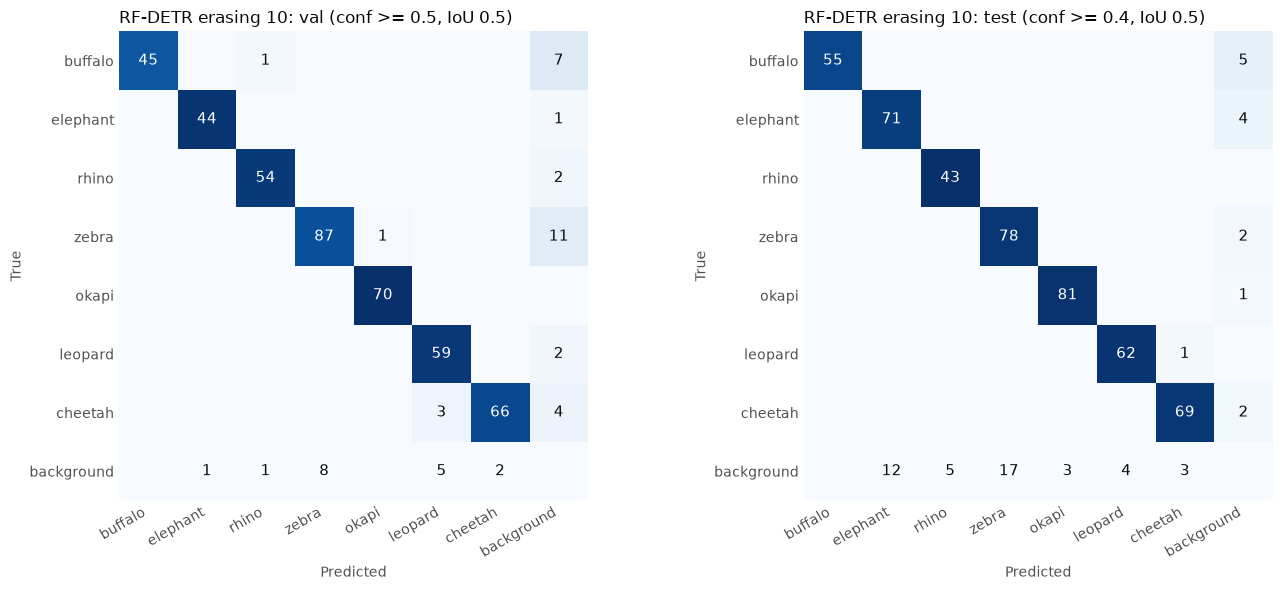

In [29]:
report_details(BASE_NAME, 'erasing_10')

## Ensemble: voting

In [30]:
def best_overlap(base, other):
    """Index of other's highest-confidence output box (conf >= VOTE_CONF) overlapping each base box (-1 if none)."""
    if len(base) == 0 or len(other) == 0:
        return np.full(len(base), -1)
    iou = sv.box_iou_batch(base.xyxy, other.xyxy)
    voting = (iou >= MATCH_IOU) & (other.confidence[None, :] >= VOTE_CONF)
    score = np.where(voting, other.confidence[None, :], -1.0)
    idx = score.argmax(axis=1)
    idx[score.max(axis=1) < 0] = -1
    return idx


def vote(base, others):
    """Majority-vote the class of every base box. Returns the voted detections and each box's outcome.
    Boxes and confidences are the base model's; only the class can change."""
    class_id = base.class_id.copy()
    outcome = np.empty(len(base), dtype=object)
    matches = [best_overlap(base, other) for other in others]

    for i in range(len(base)):
        votes = [int(base.class_id[i])] + [int(o.class_id[m[i]]) for o, m in zip(others, matches) if m[i] >= 0]
        winner, count = Counter(votes).most_common(1)[0]

        if count >= 2:
            class_id[i] = winner
            if count == 3:
                outcome[i] = 'Unanimous (3/3)'
            elif winner == base.class_id[i]:
                outcome[i] = 'Majority with base (2/3)'
            else:
                outcome[i] = 'Base overruled (2/3)'
        else:
            outcome[i] = 'No majority, base fallback'

    voted = sv.Detections(xyxy=base.xyxy.copy(), class_id=class_id, confidence=base.confidence.copy())
    return voted, outcome

## Ensemble: inference

Runs the two dropout models, then votes on the RF-DETR erasing 10 predictions from above.

In [31]:
OTHER_NAMES = [name for name in MODELS if name != BASE_NAME]
ensemble_outcomes = {}

for split in SPLITS:
    image_paths = datasets[split].image_paths
    for name in OTHER_NAMES:
        predictions[split][name] = []
    predictions[split][ENSEMBLE_NAME] = []
    ensemble_outcomes[split] = []

    for n, image_path in enumerate(image_paths, 1):
        others = [models[name].predict(image_path, threshold=PREDICT_THRESHOLD) for name in OTHER_NAMES]
        for name, detections in zip(OTHER_NAMES, others):
            predictions[split][name].append(detections)
        voted, outcome = vote(predictions[split][BASE_NAME][n - 1], others)
        predictions[split][ENSEMBLE_NAME].append(voted)
        ensemble_outcomes[split].append(outcome)
        if n % 50 == 0 or n == len(image_paths):
            print(f'{split}: inferred {n}/{len(image_paths)} images')

[2026-10-19 22:08:53] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-19 22:08:53] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


val: inferred 50/332 images
val: inferred 100/332 images
val: inferred 150/332 images
val: inferred 200/332 images
val: inferred 250/332 images
val: inferred 300/332 images
val: inferred 332/332 images
test: inferred 50/331 images
test: inferred 100/331 images
test: inferred 150/331 images
test: inferred 200/331 images
test: inferred 250/331 images
test: inferred 300/331 images
test: inferred 331/331 images


## Ensemble: overall metrics vs each model

Precision / recall / F1 are macro-averaged at IoU 0.5 and the confidence with the best F1.

In [32]:
summary_rows = []
for split in SPLITS:
    for name in [*OTHER_NAMES, ENSEMBLE_NAME]:
        results[split][name] = evaluate(predictions[split][name], targets[split])
    comparison = pd.DataFrame({name: results[split][name][0] for name in [*MODELS, ENSEMBLE_NAME]}).T
    summary_rows += [{'Split': split, 'Model': name, **metrics} for name, metrics in comparison.to_dict('index').items()]
    print(f'\n[{split}]')
    print(comparison.round(4).to_string())

summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / 'ensemble_evaluation.csv', index=False)
print('\nSaved results to:', RESULTS_DIR / 'ensemble_evaluation.csv')


[val]
                               Precision  Recall      F1   mAP50   mAP75  mAP50-95  Best-F1 confidence
RF-DETR erasing 10                0.9564  0.9345  0.9453  0.9701  0.9415    0.8794                0.50
RF-DETR erasing + dropout 0.1     0.9635  0.9341  0.9486  0.9773  0.9386    0.8740                0.65
RF-DETR erasing + dropout 0.2     0.9504  0.9242  0.9371  0.9631  0.9358    0.8525                0.70
Ensemble (majority vote)          0.9683  0.9293  0.9484  0.9687  0.9403    0.8785                0.55

[test]
                               Precision  Recall      F1   mAP50   mAP75  mAP50-95  Best-F1 confidence
RF-DETR erasing 10                0.9173  0.9689  0.9424  0.9846  0.9444    0.8916                 0.4
RF-DETR erasing + dropout 0.1     0.9595  0.9362  0.9477  0.9808  0.9357    0.8763                 0.6
RF-DETR erasing + dropout 0.2     0.9680  0.9390  0.9533  0.9776  0.9072    0.8477                 0.7
Ensemble (majority vote)          0.9523  0.9355  0.9438  

## Ensemble: per-class AP, confusion matrix, per-class precision / recall / F1

Confusion matrix at the ensemble's best-F1 confidence and IoU 0.5.


============================== [val] Ensemble (majority vote) ==============================

Per-class AP
            AP50  AP50-95
buffalo   0.9719   0.8707
elephant  0.9801   0.8764
rhino     0.9823   0.9231
zebra     0.9269   0.8229
okapi     0.9987   0.9247
leopard   0.9601   0.8331
cheetah   0.9607   0.8984

Confusion matrix (conf >= 0.55, IoU 0.5)
                 pred buffalo  pred elephant  pred rhino  pred zebra  pred okapi  pred leopard  pred cheetah  pred background
true buffalo               45              0           1           0           0             0             0                7
true elephant               0             43           0           0           0             0             0                2
true rhino                  0              0          54           0           0             0             0                2
true zebra                  0              0           0          87           1             0             0               11
true okapi  

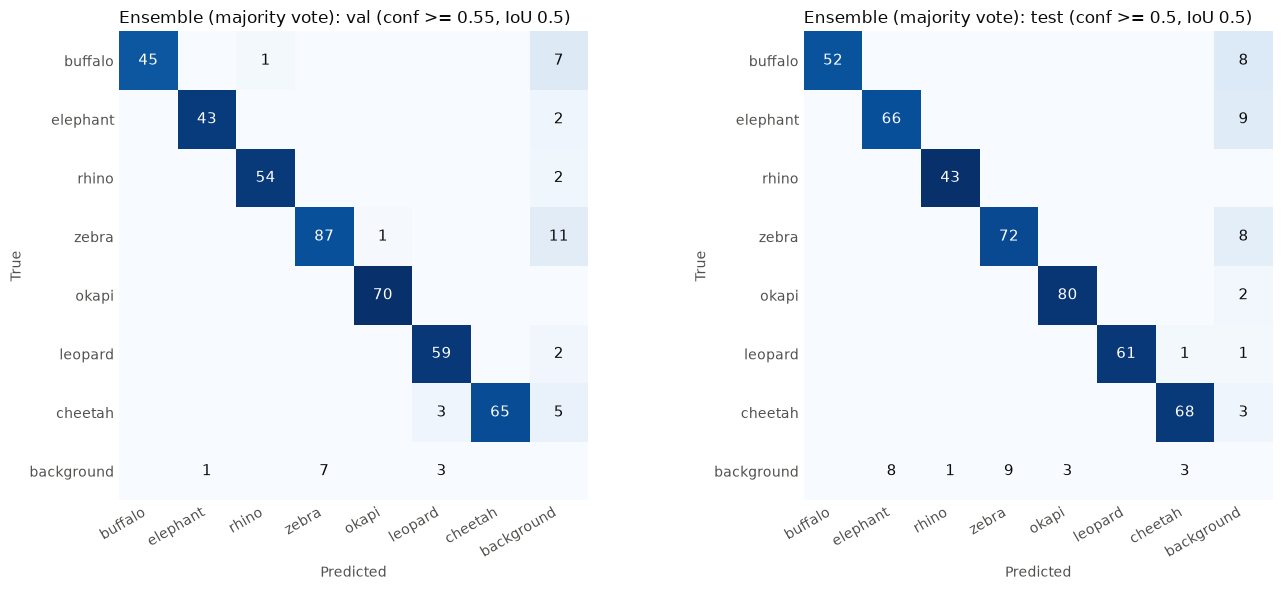

In [33]:
report_details(ENSEMBLE_NAME, 'ensemble')

## Ensemble: voting outcomes

How the vote played out on the ensemble boxes that pass the confidence cutoff.

In [34]:
for split in SPLITS:
    conf_threshold = results[split][ENSEMBLE_NAME][0]['Best-F1 confidence']
    kept = np.concatenate([o[v.confidence >= conf_threshold]
                           for o, v in zip(ensemble_outcomes[split], predictions[split][ENSEMBLE_NAME])])
    boxes = pd.Series(Counter(kept), dtype=int).sort_values(ascending=False)
    vote_stats = pd.DataFrame({'Boxes': boxes, 'Share': boxes / max(len(kept), 1)})
    print(f'\n[{split}] conf >= {conf_threshold}')
    print(vote_stats.round(4).to_string())


[val] conf >= 0.55
                            Boxes   Share
Unanimous (3/3)               415  0.9453
Majority with base (2/3)       18  0.0410
No majority, base fallback      3  0.0068
Base overruled (2/3)            3  0.0068

[test] conf >= 0.5
                            Boxes   Share
Unanimous (3/3)               441  0.9443
Majority with base (2/3)       19  0.0407
Base overruled (2/3)            4  0.0086
No majority, base fallback      3  0.0064
